# DS Startup Funding Analysis

## Startup Funding & Sector Investment Dashboard

**Project Type:** Individual IDS Capstone Project

**Objective:** To clean and analyze startup funding data, identify sector-wise investment trends, and develop an interactive dashboard.

## 1. Introduction

This project focuses on analyzing startup funding data to understand investment patterns in different sectors and cities. It aims to clean the dataset, perform exploratory data analysis, identify meaningful insights, and develop an interactive dashboard.

## 2. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the Dataset

In [2]:
import pandas as pd

file_path = "../data/raw/startup_funding.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (3044, 10)


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB


In [7]:
df.describe(include="all")

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
count,3044.000000,3044,3044,2873,2108,2864,3020,3040,2084,419
unique,NaN,1035,2459,821,1942,112,2412,55,471,72
top,NaN,30/11/2016,Swiggy,Consumer Internet,Online Lending Platform,Bangalore,Undisclosed Investors,Private Equity,"10,00,000",Series A
freq,NaN,11,8,941,11,700,39,1356,165,175
mean,1522.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,878.871435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,761.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1522.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2283.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Sr No                   0
Date dd/mm/yyyy         0
Startup Name            0
Industry Vertical     171
SubVertical           936
City  Location        180
Investors Name         24
InvestmentnType         4
Amount in USD         960
Remarks              2625
dtype: int64


In [9]:
missing_analysis = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage", ascending=False
)

display(missing_analysis.round(2))

,Missing Values,Missing Percentage
Remarks,2625,86.24
Amount in USD,960,31.54
SubVertical,936,30.75
City Location,180,5.91
Industry Vertical,171,5.62
Investors Name,24,0.79
InvestmentnType,4,0.13
Sr No,0,0.00
Date dd/mm/yyyy,0,0.00
Startup Name,0,0.00


In [10]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [11]:
print("Data types of all columns:")
print(df.dtypes)

Data types of all columns:
Sr No                 int64
Date dd/mm/yyyy      object
Startup Name         object
Industry Vertical    object
SubVertical          object
City  Location       object
Investors Name       object
InvestmentnType      object
Amount in USD        object
Remarks              object
dtype: object


In [12]:
print("Date values:")
display(df["Date dd/mm/yyyy"].head(15))

print("Funding amount values:")
display(df["Amount in USD"].head(15))

Date values:


0     09/01/2020
1     13/01/2020
2     09/01/2020
3     02/01/2020
4     02/01/2020
5     13/01/2020
6     10/01/2020
7     12/12/2019
8     06/12/2019
9     03/12/2019
10    13/12/2019
11    17/12/2019
12    16/12/2019
13    16/12/2019
14    14/12/2019
Name: Date dd/mm/yyyy, dtype: object

Funding amount values:


0     20,00,00,000
1        80,48,394
2      1,83,58,860
3        30,00,000
4        18,00,000
5        90,00,000
6     15,00,00,000
7        60,00,000
8      7,00,00,000
9      5,00,00,000
10     2,00,00,000
11     1,20,00,000
12     3,00,00,000
13       59,00,000
14       20,00,000
Name: Amount in USD, dtype: object

## 4. Data Quality Assessment

### 4.1 Date Format Validation

In [13]:
df["Date_Converted"] = pd.to_datetime(
    df["Date dd/mm/yyyy"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Invalid dates:", df["Date_Converted"].isnull().sum())

Invalid dates: 8


### 4.2 Funding Amount Validation

In [14]:
print("Funding amount values:")
display(df["Amount in USD"].head(20))

Funding amount values:


0     20,00,00,000
1        80,48,394
2      1,83,58,860
3        30,00,000
4        18,00,000
5        90,00,000
6     15,00,00,000
7        60,00,000
8      7,00,00,000
9      5,00,00,000
10     2,00,00,000
11     1,20,00,000
12     3,00,00,000
13       59,00,000
14       20,00,000
15     5,00,00,000
16    23,10,00,000
17    15,00,00,000
18        4,86,000
19       15,00,000
Name: Amount in USD, dtype: object

In [15]:
amount_text = df["Amount in USD"].astype("string").str.strip()

amount_without_commas = amount_text.str.replace(
    ",", "", regex=False
)

amount_numeric = pd.to_numeric(
    amount_without_commas,
    errors="coerce"
)

invalid_amounts = df.loc[
    amount_text.notna() & amount_numeric.isna(),
    "Amount in USD"
].value_counts()

print("Non-numeric funding values:")
display(invalid_amounts)

Non-numeric funding values:


Amount in USD
\\xc2\\xa0N/A           4
undisclosed             3
Undisclosed             3
unknown                 1
14,342,000+             1
\\xc2\\xa020,000,000    1
\\xc2\\xa016,200,000    1
\\xc2\\xa0600,000       1
\\xc2\\xa0685,000       1
\\xc2\\xa019,350,000    1
\\xc2\\xa05,000,000     1
\\xc2\\xa010,000,000    1
Name: count, dtype: int64

### 4.3 City Name Inspection

In [16]:
print("Unique city values:")
print(df["City  Location"].nunique())

display(
    df["City  Location"].value_counts().head(30)
)

Unique city values:
112


City  Location
Bangalore              700
Mumbai                 567
New Delhi              421
Gurgaon                287
Bengaluru              141
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Gurugram                50
Ahmedabad               38
Delhi                   34
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Vadodara                10
Goa                     10
Singapore                8
Coimbatore               5
Pune / US                4
\\xc2\\xa0Gurgaon        4
Kanpur                   4
Nagpur                   3
\\xc2\\xa0New Delhi      3
Bhopal                   3
Faridabad                3
Ahemadabad               2
San Francisco            2
Kormangala               2
Name: count, dtype: int64

### 4.4 Industry and Sector Inspection

In [17]:
print("Unique industry values:")
print(df["Industry Vertical"].nunique())

display(df["Industry Vertical"].value_counts().head(30))

Unique industry values:
821


Industry Vertical
Consumer Internet               941
Technology                      478
eCommerce                       186
Healthcare                       70
Finance                          62
ECommerce                        61
Logistics                        32
E-Commerce                       29
Education                        24
Food & Beverage                  23
Ed-Tech                          14
E-commerce                       12
FinTech                           9
IT                                8
Ecommerce                         8
Others                            6
Fin-Tech                          6
Food and Beverage                 6
Real Estate                       6
Online Education Platform         5
Health and Wellness               5
Logistics Tech                    5
Online Food Delivery              5
Transportation                    4
Transport                         4
Food Delivery Platform            3
Food                              3
Hyperlocal

In [18]:
invalid_date_rows = df[df["Date_Converted"].isnull()]

display(invalid_date_rows[["Startup Name", "Date dd/mm/yyyy"]])

,Startup Name,Date dd/mm/yyyy
192,Loan Tap,05/072018
2571,HandyHome,01/07/015
2606,\\xc2\\xa0Infinity Assurance,\\xc2\\xa010/7/2015
2775,Mobiefit,12/05.2015
2776,Plancess,12/05.2015
2831,The Porter,13/04.2015
3011,Wishberry,15/01.2015
3029,Corporate360,22/01//2015


In [ ]:

df["Date_Cleaned"] = (
    df["Date dd/mm/yyyy"]
    .astype("string")
    .str.replace("\u00a0", "", regex=False)
    .str.strip()
    .str.replace(".", "/", regex=False)
    .str.replace(r"/{2,}", "/", regex=True)
)


df.loc[192, "Date_Cleaned"] = "05/07/2018"
df.loc[2571, "Date_Cleaned"] = "01/07/2015"


df["Date_Cleaned"] = pd.to_datetime(
    df["Date_Cleaned"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Remaining invalid dates:",
      df["Date_Cleaned"].isnull().sum())

Remaining invalid dates: 1


In [20]:
remaining_invalid = df[df["Date_Cleaned"].isnull()]

display(
    remaining_invalid[
        ["Sr No", "Startup Name", "Date dd/mm/yyyy", "Date_Cleaned"]
    ]
)

,Sr No,Startup Name,Date dd/mm/yyyy,Date_Cleaned
2606,2607,\\xc2\\xa0Infinity Assurance,\\xc2\\xa010/7/2015,NaT


In [21]:
df.loc[df["Sr No"] == 2606, "Date_Cleaned"] = pd.to_datetime(
    "10/07/2015",
    format="%d/%m/%Y"
)

In [22]:
print("Remaining invalid dates:",
      df["Date_Cleaned"].isnull().sum())

Remaining invalid dates: 1


In [23]:
display(
    df.loc[2606, [
        "Sr No",
        "Startup Name",
        "Date dd/mm/yyyy",
        "Date_Cleaned"
    ]]
)

Sr No                                      2607
Startup Name       \\xc2\\xa0Infinity Assurance
Date dd/mm/yyyy             \\xc2\\xa010/7/2015
Date_Cleaned                                NaT
Name: 2606, dtype: object

In [24]:
df.loc[df["Sr No"] == 2607, "Date_Cleaned"] = pd.to_datetime(
    "10/07/2015",
    format="%d/%m/%Y"
)

In [25]:
print("Remaining invalid dates:", df["Date_Cleaned"].isnull().sum())

Remaining invalid dates: 0


In [ ]:

amount_text = df["Amount in USD"].astype("string")
amount_text = amount_text.str.replace("\u00a0", "", regex=False)
amount_text = amount_text.str.strip()


df["Amount_Approximate"] = amount_text.str.endswith(
    "+", na=False
)


amount_text = amount_text.str.replace(",", "", regex=False)
amount_text = amount_text.str.replace("+", "", regex=False)


df["Amount_Cleaned"] = pd.to_numeric(
    amount_text, errors="coerce"
)

print("Funding amount cleaning completed!")
print("Missing funding amounts:", df["Amount_Cleaned"].isnull().sum())
print("Data type:", df["Amount_Cleaned"].dtype)

Funding amount cleaning completed!
Missing funding amounts: 978
Data type: Float64


In [27]:
display(
    df[["Amount in USD", "Amount_Cleaned", "Amount_Approximate"]].head(20)
)

,Amount in USD,Amount_Cleaned,Amount_Approximate
0,"20,00,00,000",200000000.0,False
1,"80,48,394",8048394.0,False
2,"1,83,58,860",18358860.0,False
3,"30,00,000",3000000.0,False
4,"18,00,000",1800000.0,False
5,"90,00,000",9000000.0,False
6,"15,00,00,000",150000000.0,False
7,"60,00,000",6000000.0,False
8,"7,00,00,000",70000000.0,False
9,"5,00,00,000",50000000.0,False


In [ ]:

df["City_Cleaned"] = df["City  Location"].astype("string")


df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    "\u00a0", " ", regex=False
)


df["City_Cleaned"] = df["City_Cleaned"].str.strip()


df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    r"\s+", " ", regex=True
)

print("City whitespace cleaning completed!")

display(df["City_Cleaned"].value_counts().head(30))

City whitespace cleaning completed!


City_Cleaned
Bangalore              700
Mumbai                 567
New Delhi              421
Gurgaon                287
Bengaluru              141
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Gurugram                50
Ahmedabad               38
Delhi                   34
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Vadodara                10
Goa                     10
Singapore                8
Coimbatore               5
Pune / US                4
\\xc2\\xa0Gurgaon        4
Kanpur                   4
Nagpur                   3
\\xc2\\xa0New Delhi      3
Bhopal                   3
Faridabad                3
Ahemadabad               2
San Francisco            2
Kormangala               2
Name: count, dtype: Int64

In [ ]:

df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    "\u00a0", " ", regex=False
)


df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    r"\\xc2\\xa0", " ", regex=True
)


df["City_Cleaned"] = df["City_Cleaned"].str.strip()
df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    r"\s+", " ", regex=True
)

display(df["City_Cleaned"].value_counts().head(30))

City_Cleaned
Bangalore              700
Mumbai                 567
New Delhi              421
Gurgaon                287
Bengaluru              141
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Gurugram                50
Ahmedabad               38
Delhi                   34
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Vadodara                10
Goa                     10
Singapore                8
Coimbatore               5
Pune / US                4
\\xc2\\xa0Gurgaon        4
Kanpur                   4
Nagpur                   3
\\xc2\\xa0New Delhi      3
Bhopal                   3
Faridabad                3
Ahemadabad               2
San Francisco            2
Kormangala               2
Name: count, dtype: Int64

In [30]:
mask = df["City_Cleaned"].str.contains(
    "xc2", case=False, na=False
)

for index, value in df.loc[mask, "City_Cleaned"].items():
    print(index, repr(value))

2602 '\\\\xc2\\\\xa0Noida'
2603 '\\\\xc2\\\\xa0Bangalore'
2604 '\\\\xc2\\\\xa0Gurgaon'
2605 '\\\\xc2\\\\xa0New Delhi'
2606 '\\\\xc2\\\\xa0New Delhi'
2607 '\\\\xc2\\\\xa0Gurgaon'
2608 '\\\\xc2\\\\xa0Mumbai'
2609 '\\\\xc2\\\\xa0Gurgaon'
2610 '\\\\xc2\\\\xa0New Delhi'
2611 '\\\\xc2\\\\xa0Gurgaon'


In [ ]:

df["City_Cleaned"] = df["City_Cleaned"].str.replace(
    "\\\\xc2\\\\xa0", "", regex=False
)

df["City_Cleaned"] = df["City_Cleaned"].str.strip()

print("Unwanted characters removed!")

display(df["City_Cleaned"].value_counts().head(30))

Unwanted characters removed!


City_Cleaned
Bangalore             701
Mumbai                568
New Delhi             424
Gurgaon               291
Bengaluru             141
Pune                  105
Hyderabad              99
Chennai                97
Noida                  93
Gurugram               50
Ahmedabad              38
Delhi                  34
Jaipur                 30
Kolkata                21
Indore                 13
Chandigarh             11
Goa                    10
Vadodara               10
Singapore               8
Coimbatore              5
Kanpur                  4
Pune / US               4
Bhopal                  3
Nagpur                  3
Faridabad               3
San Francisco           2
Kormangala              2
Udaipur                 2
Bangalore/ Bangkok      2
Kochi                   2
Name: count, dtype: Int64

In [32]:
city_mapping = {
    "Bangalore": "Bengaluru",
    "Gurgaon": "Gurugram",
    "Ahemadabad": "Ahmedabad",
    "Kormangala": "Koramangala"
}

df["City_Cleaned"] = df["City_Cleaned"].replace(city_mapping)

print("City name standardization completed!")

display(df["City_Cleaned"].value_counts().head(30))

City name standardization completed!


City_Cleaned
Bengaluru             842
Mumbai                568
New Delhi             424
Gurugram              341
Pune                  105
Hyderabad              99
Chennai                97
Noida                  93
Ahmedabad              40
Delhi                  34
Jaipur                 30
Kolkata                21
Indore                 13
Chandigarh             11
Goa                    10
Vadodara               10
Singapore               8
Coimbatore              5
Kanpur                  4
Pune / US               4
Bhopal                  3
Faridabad               3
Nagpur                  3
San Francisco           2
Trivandrum              2
Udaipur                 2
Kochi                   2
Gwalior                 2
Agra                    2
Bangalore/ Bangkok      2
Name: count, dtype: Int64

In [ ]:

slash_cities = df[
    df["City_Cleaned"].str.contains("/", na=False)
]["City_Cleaned"].value_counts()

print("City entries containing slash:")
display(slash_cities)

City entries containing slash:


City_Cleaned
Pune / US                 4
Mumbai/Bengaluru          2
Bangalore/ Bangkok        2
New Delhi / US            2
Bangalore / SFO           2
India/US                  2
Seattle / Bangalore       1
SFO / Bangalore           1
Pune / Dubai              1
Pune/Seattle              1
Mumbai / UK               1
Hyderabad/USA             1
Bangalore / Palo Alto     1
India/Singapore           1
Mumbai / NY               1
USA/India                 1
Goa/Hyderabad             1
Noida / Singapore         1
Chennai/ Singapore        1
Pune / Singapore          1
Bangalore / San Mateo     1
New York/ India           1
US/India                  1
Gurgaon / SFO             1
Bangalore / USA           1
New Delhi/ Houston        1
Mumbai / Global           1
India / US                1
New Delhi / California    1
Dallas / Hyderabad        1
Name: count, dtype: Int64

In [34]:
print("All unique city names:")
display(sorted(df["City_Cleaned"].dropna().unique()))

All unique city names:


['Agra',
 'Ahemdabad',
 'Ahmedabad',
 'Amritsar',
 'Andheri',
 'Bangalore / Palo Alto',
 'Bangalore / SFO',
 'Bangalore / San Mateo',
 'Bangalore / USA',
 'Bangalore/ Bangkok',
 'Belgaum',
 'Bengaluru',
 'Bengaluru and Gurugram',
 'Bhopal',
 'Bhubaneswar',
 'Bhubneswar',
 'Boston',
 'Burnsville',
 'California',
 'Chandigarh',
 'Chembur',
 'Chennai',
 'Chennai/ Singapore',
 'Coimbatore',
 'Dallas / Hyderabad',
 'Delhi',
 'Delhi & Cambridge',
 'Faridabad',
 'Gaya',
 'Goa',
 'Goa/Hyderabad',
 'Gurgaon / SFO',
 'Gurugram',
 'Gwalior',
 'Haryana',
 'Hubli',
 'Hyderabad',
 'Hyderabad/USA',
 'India',
 'India / US',
 'India/Singapore',
 'India/US',
 'Indore',
 'Jaipur',
 'Jodhpur',
 'Kanpur',
 'Karnataka',
 'Karur',
 'Kerala',
 'Kochi',
 'Kolkata',
 'Kolkatta',
 'Koramangala',
 'Kozhikode',
 'London',
 'Lucknow',
 'Menlo Park',
 'Missourie',
 'Mumbai',
 'Mumbai / Global',
 'Mumbai / NY',
 'Mumbai / UK',
 'Mumbai/Bengaluru',
 'Nagpur',
 'Nairobi',
 'New Delhi',
 'New Delhi / California',
 'New 

In [ ]:
additional_city_mapping = {
    "Ahemdabad": "Ahmedabad",
    "Bhubneswar": "Bhubaneswar",
    "Kolkatta": "Kolkata",
    "Nw Delhi": "New Delhi"
}

df["City_Cleaned"] = df["City_Cleaned"].replace(
    additional_city_mapping
)


df["City_Cleaned"] = (
    df["City_Cleaned"]
    .str.replace(r",+$", "", regex=True)
    .str.strip()
)

print("Additional city standardization completed!")

display(df["City_Cleaned"].value_counts().head(30))

Additional city standardization completed!


City_Cleaned
Bengaluru             842
Mumbai                568
New Delhi             425
Gurugram              341
Pune                  105
Hyderabad              99
Chennai                97
Noida                  93
Ahmedabad              41
Delhi                  34
Jaipur                 30
Kolkata                22
Indore                 13
Chandigarh             11
Goa                    10
Vadodara               10
Singapore               8
Coimbatore              5
Kanpur                  4
Pune / US               4
Nagpur                  3
Bhopal                  3
Faridabad               3
Udupi                   2
Agra                    2
Bangalore/ Bangkok      2
Siliguri                2
Udaipur                 2
Surat                   2
Bhubaneswar             2
Name: count, dtype: Int64

In [36]:
print("Missing city values:",
      df["City_Cleaned"].isnull().sum())

print("Total unique city values:",
      df["City_Cleaned"].nunique())

print("Total records:",
      len(df))

Missing city values: 180
Total unique city values: 100
Total records: 3044


In [37]:
remaining = df[
    df["City_Cleaned"].str.contains(
        r"\\xc2|\\xa0", regex=True, na=False
    )
]

print("Records with unwanted escaped characters:", len(remaining))

Records with unwanted escaped characters: 0


In [ ]:

df["Industry_Cleaned"] = (
    df["Industry Vertical"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)


df["Industry_Cleaned"] = (
    df["Industry_Cleaned"].str.title()
)

print("Industry text cleaning completed!")

print("Missing industry values:",
      df["Industry_Cleaned"].isnull().sum())

print("Unique industry values:",
      df["Industry_Cleaned"].nunique())

display(
    df["Industry_Cleaned"].value_counts().head(30)
)

Industry text cleaning completed!
Missing industry values: 171
Unique industry values: 799


Industry_Cleaned
Consumer Internet               942
Technology                      478
Ecommerce                       258
Healthcare                       71
Finance                          62
E-Commerce                       41
Logistics                        32
Education                        24
Food & Beverage                  23
Ed-Tech                          15
Fintech                          10
It                                8
Fin-Tech                          6
Health And Wellness               6
Food And Beverage                 6
Real Estate                       6
Others                            6
Online Food Delivery              5
Edtech                            5
Online Education Platform         5
Logistics Tech                    5
Transportation                    4
Saas                              4
Food Delivery Platform            4
Transport                         4
Hyperlocal Handyman Services      4
Fmcg                              3
Food       

In [39]:
industry_mapping = {
    "E-Commerce": "Ecommerce",
    "Fin-Tech": "Fintech",
    "Ed-Tech": "EdTech",
    "Edtech": "EdTech",
    "Food And Beverage": "Food & Beverage",
    "Food & Beverages": "Food & Beverage",
    "Information Technology": "IT",
    "Saas": "SaaS"
}

df["Industry_Cleaned"] = df["Industry_Cleaned"].replace(
    industry_mapping
)

print("Industry standardization completed!")

display(
    df["Industry_Cleaned"].value_counts().head(30)
)

Industry standardization completed!


Industry_Cleaned
Consumer Internet                942
Technology                       478
Ecommerce                        299
Healthcare                        71
Finance                           62
Food & Beverage                   32
Logistics                         32
Education                         24
EdTech                            20
Fintech                           16
It                                 8
Health And Wellness                6
Others                             6
Real Estate                        6
Logistics Tech                     5
Online Food Delivery               5
Online Education Platform          5
SaaS                               4
Transport                          4
Hyperlocal Handyman Services       4
Transportation                     4
Food Delivery Platform             4
Big Data & Analytics Platform      3
IT                                 3
Food And Beverages                 3
Automobile                         3
Food                 

In [40]:
additional_industry_mapping = {
    "It": "IT",
    "Food And Beverages": "Food & Beverage",
    "Fmcg": "FMCG"
}

df["Industry_Cleaned"] = df["Industry_Cleaned"].replace(
    additional_industry_mapping
)

print("Additional industry corrections completed!")

display(
    df["Industry_Cleaned"].value_counts().head(30)
)

Additional industry corrections completed!


Industry_Cleaned
Consumer Internet                942
Technology                       478
Ecommerce                        299
Healthcare                        71
Finance                           62
Food & Beverage                   35
Logistics                         32
Education                         24
EdTech                            20
Fintech                           16
IT                                11
Others                             6
Real Estate                        6
Health And Wellness                6
Logistics Tech                     5
Online Food Delivery               5
Online Education Platform          5
Food Delivery Platform             4
Transportation                     4
Transport                          4
SaaS                               4
Hyperlocal Handyman Services       4
Services                           3
Automobile                         3
Social Media                       3
Big Data & Analytics Platform      3
FMCG                 

In [41]:
print("Missing industry values:",
      df["Industry_Cleaned"].isnull().sum())

print("Unique industry categories:",
      df["Industry_Cleaned"].nunique())

Missing industry values: 171
Unique industry categories: 792


In [42]:
print("Unique sub-vertical values:",
      df["SubVertical"].nunique())

print("\nTop 30 sub-verticals:")

display(
    df["SubVertical"]
    .value_counts()
    .head(30)
)

print("\nMissing sub-vertical values:",
      df["SubVertical"].isnull().sum())

Unique sub-vertical values: 1942

Top 30 sub-verticals:


SubVertical
Online Lending Platform                          11
Online Pharmacy                                  10
Food Delivery Platform                            8
Online Lending                                    5
Online Learning Platform                          5
Online lending platform                           5
Education                                         5
Online Education Platform                         5
Non-Banking Financial Company                     4
Online Food Delivery                              4
Agri-tech                                         3
Online Insurance Aggregator                       3
Online Furniture Store                            3
Online learning platform                          3
SaaS                                              3
Online Marketplace                                3
ECommerce Marketplace                             3
Online Food Delivery Platform                     3
B2B Marketplace                                   3



Missing sub-vertical values: 936


In [ ]:

df["SubVertical_Cleaned"] = (
    df["SubVertical"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)


df["SubVertical_Cleaned"] = (
    df["SubVertical_Cleaned"].str.title()
)

print("SubVertical text cleaning completed!")

print("Missing values:",
      df["SubVertical_Cleaned"].isnull().sum())

print("Unique values:",
      df["SubVertical_Cleaned"].nunique())

display(
    df["SubVertical_Cleaned"].value_counts().head(30)
)

SubVertical text cleaning completed!
Missing values: 936
Unique values: 1883


SubVertical_Cleaned
Online Lending Platform             21
Online Pharmacy                     10
Food Delivery Platform              10
Online Learning Platform             9
Online Food Delivery Platform        5
Online Lending                       5
Non-Banking Financial Company        5
Education                            5
Online Education Platform            5
Online Marketplace                   5
Data Analytics Platform              4
Ecommerce Marketplace                4
Online Payment Gateway               4
Online Consumer Lending Platform     4
Online Food Delivery                 4
Online Insurance Platform            4
Micro Lending Platform               4
Co-Working Spaces                    4
Online Gifting Platform              4
Health-Tech Platform                 3
Agri-Tech                            3
Online Furniture Store               3
Online Insurance Aggregator          3
Healthy Food Delivery Platform       3
E-Learning                           3
Saas 

In [44]:
subvertical_mapping = {
    "Saas": "SaaS"
}

df["SubVertical_Cleaned"] = df["SubVertical_Cleaned"].replace(
    subvertical_mapping
)

print("SubVertical standardization completed!")

display(
    df["SubVertical_Cleaned"].value_counts().head(30)
)

SubVertical standardization completed!


SubVertical_Cleaned
Online Lending Platform             21
Online Pharmacy                     10
Food Delivery Platform              10
Online Learning Platform             9
Online Food Delivery Platform        5
Online Lending                       5
Non-Banking Financial Company        5
Education                            5
Online Education Platform            5
Online Marketplace                   5
Data Analytics Platform              4
Ecommerce Marketplace                4
Online Payment Gateway               4
Online Consumer Lending Platform     4
Online Food Delivery                 4
Online Insurance Platform            4
Micro Lending Platform               4
Co-Working Spaces                    4
Online Gifting Platform              4
Health-Tech Platform                 3
Agri-Tech                            3
Online Furniture Store               3
Online Insurance Aggregator          3
Healthy Food Delivery Platform       3
E-Learning                           3
SaaS 

In [45]:
print("Missing SubVertical values:",
      df["SubVertical_Cleaned"].isnull().sum())

print("Unique SubVertical values:",
      df["SubVertical_Cleaned"].nunique())

Missing SubVertical values: 936
Unique SubVertical values: 1883


In [46]:
print("Unique investment types:",
      df["InvestmentnType"].nunique())

print("\nInvestment type counts:")

display(
    df["InvestmentnType"].value_counts()
)

print("\nMissing investment types:",
      df["InvestmentnType"].isnull().sum())

Unique investment types: 55

Investment type counts:


InvestmentnType
Private Equity                 1356
Seed Funding                   1355
Seed/ Angel Funding              60
Seed / Angel Funding             47
Seed\\nFunding                   30
Debt Funding                     25
Series A                         24
Seed/Angel Funding               23
Series B                         20
Series C                         14
Series D                         12
Angel / Seed Funding              8
Seed Round                        7
Seed                              4
Private Equity Round              4
Pre-Series A                      4
Seed / Angle Funding              3
Equity                            2
Series E                          2
Corporate Round                   2
Venture Round                     2
Series F                          2
pre-Series A                      2
Seed Funding Round                1
Single Venture                    1
Maiden Round                      1
pre-series A                      1
Funding Roun


Missing investment types: 4


In [ ]:

df["Investment_Type_Cleaned"] = (
    df["InvestmentnType"]
    .astype("string")
    .str.strip()
)


df["Investment_Type_Cleaned"] = (
    df["Investment_Type_Cleaned"]
    .str.replace(r"\\n", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


investment_mapping = {
    "Seed/ Angel Funding": "Seed/Angel Funding",
    "Seed / Angel Funding": "Seed/Angel Funding",
    "Angel / Seed Funding": "Seed/Angel Funding",
    "Seed / Angle Funding": "Seed/Angel Funding",
    "Seed /Angel Funding": "Seed/Angel Funding",
    "Private Equity Round": "Private Equity",
    "PrivateEquity": "Private Equity",
    "Debt-Funding": "Debt Funding",
    "Pre-Series A": "Pre-Series A",
    "pre-Series A": "Pre-Series A",
    "pre-series A": "Pre-Series A",
    "Pre-series A": "Pre-Series A",
    "Pre Series A": "Pre-Series A",
    "Seed Funding Round": "Seed Funding",
    "Seed funding": "Seed Funding",
    "Crowd funding": "Crowd Funding"
}

df["Investment_Type_Cleaned"] = (
    df["Investment_Type_Cleaned"].replace(investment_mapping)
)

print("Investment type cleaning completed!")

display(
    df["Investment_Type_Cleaned"].value_counts()
)

Investment type cleaning completed!


Investment_Type_Cleaned
Private Equity                 1361
Seed Funding                   1357
Seed/Angel Funding              141
Seed\ Funding                    30
Debt Funding                     26
Series A                         24
Series B                         20
Series C                         14
Series D                         12
Pre-Series A                      9
Seed Round                        7
Seed                              4
Series F                          2
Venture Round                     2
Crowd Funding                     2
Corporate Round                   2
Series E                          2
Equity                            2
Maiden Round                      1
Single Venture                    1
Angel                             1
Funding Round                     1
Series H                          1
Venture                           1
Series G                          1
Bridge Round                      1
Venture - Series Unknown          1
Ange

In [48]:
print("Missing investment types:",
      df["Investment_Type_Cleaned"].isnull().sum())

print("Unique investment types:",
      df["Investment_Type_Cleaned"].nunique())

Missing investment types: 4
Unique investment types: 41


In [49]:
for value in df["Investment_Type_Cleaned"].dropna().unique():
    if "\\" in value:
        print(repr(value))

'Seed\\ Funding'
'Private\\ Equity'


In [50]:
df["Investment_Type_Cleaned"] = (
    df["Investment_Type_Cleaned"]
    .str.replace("\\", "", regex=False)
    .str.strip()
)

display(df["Investment_Type_Cleaned"].value_counts())

Investment_Type_Cleaned
Seed Funding                   1387
Private Equity                 1362
Seed/Angel Funding              141
Debt Funding                     26
Series A                         24
Series B                         20
Series C                         14
Series D                         12
Pre-Series A                      9
Seed Round                        7
Seed                              4
Series E                          2
Corporate Round                   2
Venture Round                     2
Series F                          2
Equity                            2
Crowd Funding                     2
Venture                           1
Funding Round                     1
Single Venture                    1
Series H                          1
Maiden Round                      1
Series G                          1
Angel Round                       1
Series J                          1
Angel                             1
Venture - Series Unknown          1
Inho

In [51]:
print("Missing investment types:",
      df["Investment_Type_Cleaned"].isnull().sum())

print("Unique investment types:",
      df["Investment_Type_Cleaned"].nunique())

Missing investment types: 4
Unique investment types: 39


In [52]:
display(df["Investors Name"].value_counts().head(20))

Investors Name
Undisclosed Investors       39
Undisclosed investors       30
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Undisclosed Investor        12
Accel Partners              12
Venture Catalysts           11
Undisclosed                 11
undisclosed investors       11
Brand Capital               11
SAIF Partners               10
RoundGlass Partners         10
Nexus Venture Partners       9
Undisclosed investor         9
Info Edge (India) Ltd        9
Tiger Global                 8
Trifecta Capital             8
Name: count, dtype: int64

In [ ]:

df["Investors_Cleaned"] = (
    df["Investors Name"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)


investor_mapping = {
    "Undisclosed investors": "Undisclosed Investors",
    "undisclosed investors": "Undisclosed Investors",
    "Undisclosed investor": "Undisclosed Investors",
    "Undisclosed": "Undisclosed Investors"
}

df["Investors_Cleaned"] = df["Investors_Cleaned"].replace(
    investor_mapping
)

print("Investor name cleaning completed!")

display(df["Investors_Cleaned"].value_counts().head(20))

Investor name cleaning completed!


Investors_Cleaned
Undisclosed Investors       100
Ratan Tata                   25
Indian Angel Network         23
Kalaari Capital              16
Sequoia Capital              15
Group of Angel Investors     15
Undisclosed Investor         12
Accel Partners               12
Venture Catalysts            11
Brand Capital                11
RoundGlass Partners          10
SAIF Partners                10
Info Edge (India) Ltd         9
Nexus Venture Partners        9
Trifecta Capital              8
Tiger Global                  8
Blume Ventures                8
Unitus Seed Fund              8
Tiger Global Management       7
Matrix Partners               7
Name: count, dtype: Int64

In [54]:
df["Investors_Cleaned"] = df["Investors_Cleaned"].replace({
    "Undisclosed Investor": "Undisclosed Investors"
})

display(df["Investors_Cleaned"].value_counts().head(20))

Investors_Cleaned
Undisclosed Investors       112
Ratan Tata                   25
Indian Angel Network         23
Kalaari Capital              16
Sequoia Capital              15
Group of Angel Investors     15
Accel Partners               12
Brand Capital                11
Venture Catalysts            11
RoundGlass Partners          10
SAIF Partners                10
Info Edge (India) Ltd         9
Nexus Venture Partners        9
Blume Ventures                8
Tiger Global                  8
Unitus Seed Fund              8
Trifecta Capital              8
Matrix Partners               7
YouWeCan Ventures             7
Tiger Global Management       7
Name: count, dtype: Int64

In [55]:
print("Missing Remarks:",
      df["Remarks"].isnull().sum())

print("Non-missing Remarks:",
      df["Remarks"].notnull().sum())

display(df["Remarks"].dropna().value_counts().head(20))

Missing Remarks: 2625
Non-missing Remarks: 419


Remarks
Series A                              175
Series B                               63
Pre-Series A                           37
Series C                               28
Series D                               11
Strategic Investment                   11
Late Stage                              9
Strategic Funding                       6
At the 10 minute million event          6
pre-Series A                            6
Bridge Round                            4
\\xc2\\xa0Series A                      2
Bridge Funding                          2
part of $40M Series B round             1
Yet to Launch platform                  1
Series B (includes Debt financing)      1
Pre-Series A Bridge                     1
Funding happened in Sept 2015           1
Bridge funding                          1
2nd seed funding                        1
Name: count, dtype: int64

In [56]:
df["Remarks_Cleaned"] = (
    df["Remarks"]
    .astype("string")
    .str.replace(r"\\xc2\\xa0", "", regex=True)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Remarks cleaning completed!")

display(df["Remarks_Cleaned"].value_counts().head(20))

Remarks cleaning completed!


Remarks_Cleaned
Series A                              175
Series B                               63
Pre-Series A                           37
Series C                               28
Series D                               11
Strategic Investment                   11
Late Stage                              9
Strategic Funding                       6
At the 10 minute million event          6
pre-Series A                            6
Bridge Round                            4
\\xc2\\xa0Series A                      2
Bridge Funding                          2
part of $40M Series B round             1
Yet to Launch platform                  1
Series B (includes Debt financing)      1
Pre-Series A Bridge                     1
Funding happened in Sept 2015           1
Bridge funding                          1
2nd seed funding                        1
Name: count, dtype: Int64

In [57]:
for value in df["Remarks_Cleaned"].dropna().unique():
    if "\\" in value:
        print(repr(value))

'Series C\\\\n(More here)'
'\\\\xc2\\\\xa0Series B'
'\\\\xc2\\\\xa0Late Stage'
'\\\\xc2\\\\xa0Series A'


In [58]:
df["Remarks_Cleaned"] = (
    df["Remarks_Cleaned"]
    .str.replace(r"\\xc2\\xa0", "", regex=True)
    .str.replace(r"\\n", " ", regex=True)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Remarks cleaning completed!")

display(df["Remarks_Cleaned"].value_counts().head(20))

Remarks cleaning completed!


Remarks_Cleaned
Series A                              175
Series B                               63
Pre-Series A                           37
Series C                               28
Series D                               11
Strategic Investment                   11
Late Stage                              9
Strategic Funding                       6
At the 10 minute million event          6
pre-Series A                            6
Bridge Round                            4
\\xc2\\xa0Series A                      2
Bridge Funding                          2
part of $40M Series B round             1
Yet to Launch platform                  1
Series B (includes Debt financing)      1
Pre-Series A Bridge                     1
Funding happened in Sept 2015           1
Bridge funding                          1
2nd seed funding                        1
Name: count, dtype: Int64

In [59]:
df["Remarks_Cleaned"] = (
    df["Remarks_Cleaned"]
    .str.replace("\\\\xc2\\\\xa0", "", regex=False)
    .str.replace("\\\\n", " ", regex=False)
    .str.strip()
)

display(df["Remarks_Cleaned"].value_counts().head(20))

Remarks_Cleaned
Series A                                     177
Series B                                      64
Pre-Series A                                  37
Series C                                      28
Strategic Investment                          11
Series D                                      11
Late Stage                                    10
Strategic Funding                              6
pre-Series A                                   6
At the 10 minute million event                 6
Bridge Round                                   4
Bridge Funding                                 2
Additional investment from parent company      1
Yet to Launch                                  1
Bridge funding                                 1
Pre-Series A Bridge                            1
Funding happened in Sept 2015                  1
2nd seed funding                               1
part of $40M Series B round                    1
Additional Funding                             1
Name

In [60]:
for value in df["Remarks_Cleaned"].dropna().unique():
    if "\\" in value:
        print(repr(value))

'Series C\\ (More here)'


In [61]:
df["Remarks_Cleaned"] = (
    df["Remarks_Cleaned"]
    .str.replace("\\", "", regex=False)
    .str.strip()
)

display(
    df[df["Remarks_Cleaned"].str.contains(
        "Series C", case=False, na=False
    )][["Remarks", "Remarks_Cleaned"]]
)

,Remarks,Remarks_Cleaned
2128,Series C,Series C
2238,Series C,Series C
2309,Strategic Funding (Series C),Strategic Funding (Series C)
2342,Series C,Series C
2378,Series C,Series C
2387,Series C,Series C
2489,Series C,Series C
2493,Series C,Series C
2514,Series C,Series C
2575,Series C\\n(More here),Series C (More here)


In [62]:
display(
    df.loc[
        df["Sr No"] == 2493,
        ["Sr No", "Remarks", "Remarks_Cleaned"]
    ]
)

,Sr No,Remarks,Remarks_Cleaned
2492,2493,NaN,<NA>


In [63]:
cleaned_columns = [
    "Date_Cleaned",
    "Amount_Cleaned",
    "City_Cleaned",
    "Industry_Cleaned",
    "SubVertical_Cleaned",
    "Investment_Type_Cleaned",
    "Investors_Cleaned",
    "Remarks_Cleaned"
]

cleaning_summary = pd.DataFrame({
    "Column": cleaned_columns,
    "Missing Values": [
        df[col].isnull().sum() for col in cleaned_columns
    ],
    "Unique Values": [
        df[col].nunique() for col in cleaned_columns
    ],
    "Data Type": [
        str(df[col].dtype) for col in cleaned_columns
    ]
})

display(cleaning_summary)

,Column,Missing Values,Unique Values,Data Type
0,Date_Cleaned,0,1030,datetime64[ns]
1,Amount_Cleaned,978,454,Float64
2,City_Cleaned,180,100,string
3,Industry_Cleaned,171,792,string
4,SubVertical_Cleaned,936,1883,string
5,Investment_Type_Cleaned,4,39,string
6,Investors_Cleaned,24,2407,string
7,Remarks_Cleaned,2625,69,string


In [64]:
df_clean = df.copy()

In [65]:
missing_summary = pd.DataFrame({
    "Missing Values": df_clean[cleaned_columns].isnull().sum(),
    "Missing Percentage": (
        df_clean[cleaned_columns].isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
Date_Cleaned,0,0.00
Amount_Cleaned,978,32.13
City_Cleaned,180,5.91
Industry_Cleaned,171,5.62
SubVertical_Cleaned,936,30.75
Investment_Type_Cleaned,4,0.13
Investors_Cleaned,24,0.79
Remarks_Cleaned,2625,86.24


In [ ]:

df_processed = df_clean.copy()


categorical_columns = [
    "City_Cleaned",
    "Industry_Cleaned",
    "SubVertical_Cleaned",
    "Investment_Type_Cleaned",
    "Investors_Cleaned"
]


for col in categorical_columns:
    df_processed[col] = df_processed[col].fillna("Unknown")

print("Categorical missing values handled successfully!")

display(df_processed[categorical_columns].isnull().sum())

Categorical missing values handled successfully!


City_Cleaned               0
Industry_Cleaned           0
SubVertical_Cleaned        0
Investment_Type_Cleaned    0
Investors_Cleaned          0
dtype: int64

In [67]:
remaining_missing = pd.DataFrame({
    "Missing Values": df_processed.isnull().sum()
})

display(remaining_missing[remaining_missing["Missing Values"] > 0])

,Missing Values
Industry Vertical,171
SubVertical,936
City Location,180
Investors Name,24
InvestmentnType,4
Amount in USD,960
Remarks,2625
Date_Converted,8
Amount_Cleaned,978
Remarks_Cleaned,2625


In [68]:
final_columns = [
    "Date_Cleaned",
    "Amount_Cleaned",
    "City_Cleaned",
    "Industry_Cleaned",
    "SubVertical_Cleaned",
    "Investment_Type_Cleaned",
    "Investors_Cleaned",
    "Remarks_Cleaned"
]

display(df_processed[final_columns].isnull().sum())

Date_Cleaned                  0
Amount_Cleaned              978
City_Cleaned                  0
Industry_Cleaned              0
SubVertical_Cleaned           0
Investment_Type_Cleaned       0
Investors_Cleaned             0
Remarks_Cleaned            2625
dtype: int64

In [ ]:

duplicate_count = df_processed.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [70]:
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Leading/trailing spaces:",
          df_processed[col].ne(df_processed[col].str.strip()).sum())


Column: City_Cleaned
Leading/trailing spaces: 0

Column: Industry_Cleaned
Leading/trailing spaces: 0

Column: SubVertical_Cleaned
Leading/trailing spaces: 0

Column: Investment_Type_Cleaned
Leading/trailing spaces: 0

Column: Investors_Cleaned
Leading/trailing spaces: 0


In [71]:
display(df_processed["Amount_Cleaned"].describe())

count              2066.0
mean      18427918.617725
std      121344085.654612
min               16000.0
25%              471250.0
50%             1725000.0
75%             8000000.0
max          3900000000.0
Name: Amount_Cleaned, dtype: Float64

In [ ]:

Q1 = df_processed["Amount_Cleaned"].quantile(0.25)
Q3 = df_processed["Amount_Cleaned"].quantile(0.75)


IQR = Q3 - Q1


lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


outliers = df_processed[
    (df_processed["Amount_Cleaned"] < lower_limit) |
    (df_processed["Amount_Cleaned"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of outliers:", len(outliers))

Q1: 471250.0
Q3: 8000000.0
IQR: 7528750.0
Lower Limit: -10821875.0
Upper Limit: 19293125.0
Number of outliers: 283


In [73]:
outlier_details = outliers[
    [
        "Sr No",
        "Startup Name",
        "Amount_Cleaned",
        "Industry_Cleaned",
        "City_Cleaned"
    ]
].sort_values(
    by="Amount_Cleaned",
    ascending=False
)

display(outlier_details.head(10))

,Sr No,Startup Name,Amount_Cleaned,Industry_Cleaned,City_Cleaned
60,61,Rapido Bike Taxi,3900000000.0,Transportation,Bengaluru
651,652,Flipkart,2500000000.0,Ecommerce,Bengaluru
966,967,Flipkart,1400000000.0,Ecommerce,Bengaluru
830,831,Paytm,1400000000.0,Ecommerce,Bengaluru
31,32,Paytm,1000000000.0,Fintech,Noida
2648,2649,Flipkart.com,700000000.0,Online Marketplace,Bengaluru
2459,2460,Paytm,680000000.0,E-Commerce & M-Commerce Platform,New Delhi
188,189,True North,600000000.0,Finance,Mumbai
33,34,Udaan,585000000.0,B2B,Bengaluru
2244,2245,Ola,500000000.0,Car Aggregator & Retail Mobile App,Bengaluru


In [74]:
display(
    df_processed.loc[
        df_processed["Sr No"].isin([189, 61, 652]),
        ["Sr No", "Startup Name", "Amount in USD", "Amount_Cleaned"]
    ]
)

,Sr No,Startup Name,Amount in USD,Amount_Cleaned
60,61,Rapido Bike Taxi,"3,90,00,00,000",3900000000.0
188,189,True North,"60,00,00,000",600000000.0
651,652,Flipkart,"2,50,00,00,000",2500000000.0


In [75]:
df_processed["Is_Outlier"] = (
    df_processed["Amount_Cleaned"] > upper_limit
)

print("Outliers:", df_processed["Is_Outlier"].sum())
print("Normal records:",
      (df_processed["Is_Outlier"] == False).sum())

Outliers: 283
Normal records: 1783


In [76]:
print("Final dataset shape:", df_processed.shape)

print("\nDuplicate records:",
      df_processed.duplicated().sum())

print("\nMissing values in processed columns:")
display(df_processed[final_columns].isnull().sum())

print("\nOutlier count:",
      df_processed["Is_Outlier"].sum())

Final dataset shape: (3044, 21)

Duplicate records: 0

Missing values in processed columns:


Date_Cleaned                  0
Amount_Cleaned              978
City_Cleaned                  0
Industry_Cleaned              0
SubVertical_Cleaned           0
Investment_Type_Cleaned       0
Investors_Cleaned             0
Remarks_Cleaned            2625
dtype: int64


Outlier count: 283


In [77]:
import os

os.makedirs("../data/processed", exist_ok=True)

df_processed.to_csv(
    "../data/processed/startup_funding_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset, identify patterns, discover trends and obtain meaningful insights using statistical summaries and visualizations.

### 1. Year-wise Startup Funding Analysis

This analysis examines the number of startup funding records in each year to understand how startup funding activity has changed over time.

In [ ]:


df_processed["Year"] = df_processed["Date_Cleaned"].dt.year



yearly_funding = (
    df_processed["Year"]
    .value_counts()
    .sort_index()
)

display(yearly_funding)

Year
2015    936
2016    993
2017    687
2018    310
2019    111
2020      7
Name: count, dtype: int64

### 2. Year-wise Startup Funding Visualization

A bar chart is used to visualize the number of startup funding records across different years. It helps identify the years with higher and lower funding activity in the available dataset.

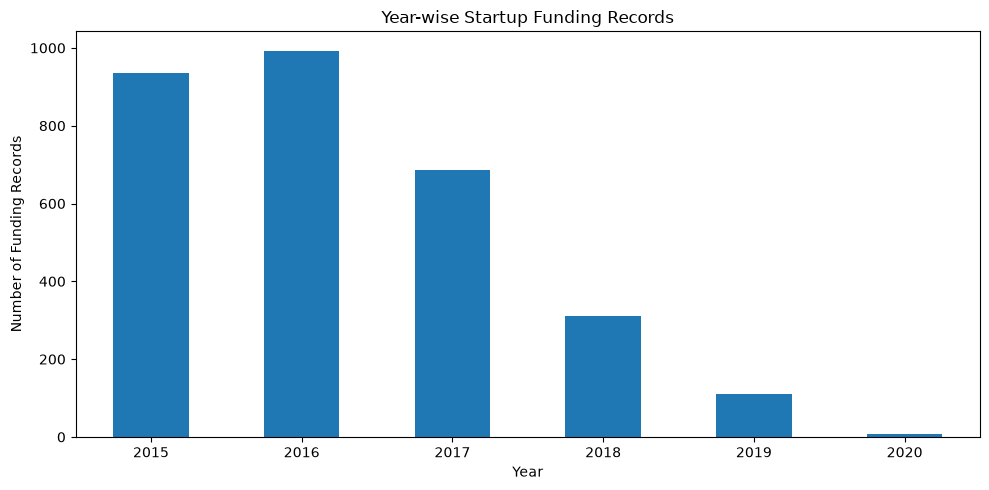

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

yearly_funding.plot(kind="bar")

plt.title("Year-wise Startup Funding Records")
plt.xlabel("Year")
plt.ylabel("Number of Funding Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Observation:**

The year-wise analysis shows that 2016 recorded the highest number of startup funding entries, with 993 records, followed by 2015 with 936 records. The number of recorded entries declined significantly from 2017 onwards. The dataset contains only 7 entries for 2020.

This indicates a declining trend in the number of funding records available in the dataset after 2016. However, it does not necessarily represent the overall funding trend of the entire startup ecosystem.

### 3. Year-wise Total Funding Amount Analysis

This analysis calculates the total recorded funding amount for each year. It helps identify which years received higher investment amounts and how the funding distribution changed over time.

In [ ]:


yearly_amount = (
    df_processed.groupby("Year")["Amount_Cleaned"]
    .sum()
)

display(yearly_amount)

Year
2015         8601187368.0
2016         3828088608.0
2017        10429309730.0
2018         5122368369.0
2019    9700918535.219999
2020          390207254.0
Name: Amount_Cleaned, dtype: Float64

### 4. Year-wise Total Funding Amount Visualization

A bar chart is used to compare the total recorded funding amounts across different years. The amounts are converted into billions to make the visualization easier to read.

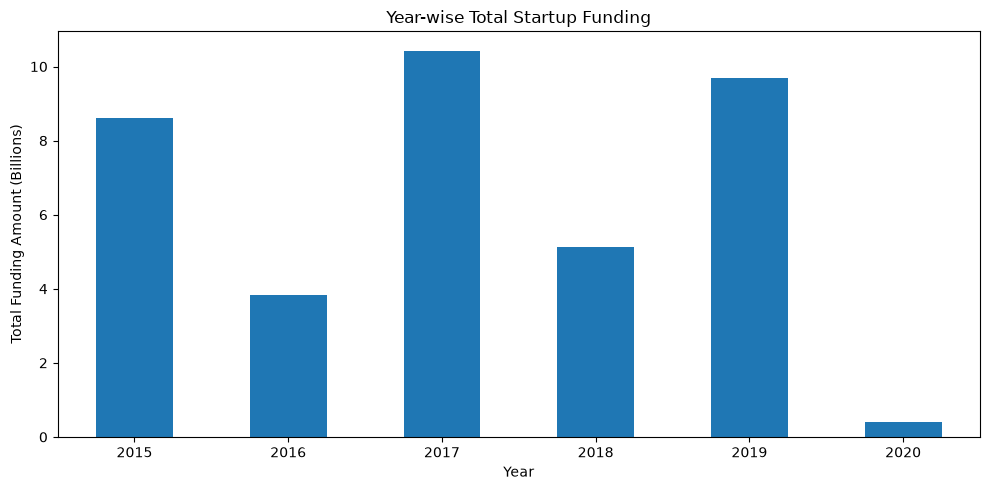

In [ ]:


yearly_amount_billions = yearly_amount / 1_000_000_000

plt.figure(figsize=(10, 5))

yearly_amount_billions.plot(kind="bar")

plt.title("Year-wise Total Startup Funding")
plt.xlabel("Year")
plt.ylabel("Total Funding Amount (Billions)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### 5. Industry-wise Total Funding Analysis

This analysis identifies the industries that received the highest total funding amounts. It helps us understand which business sectors attracted more investment in the available dataset.

In [ ]:


industry_funding = (
    df_processed.groupby("Industry_Cleaned")["Amount_Cleaned"]
    .sum()
    .sort_values(ascending=False)
)



display(industry_funding.head(10))

Industry_Cleaned
Ecommerce                           8260735692.54
Consumer Internet                    6254084245.0
Transportation                       3916632394.0
Technology                           2229707930.0
Finance                              1971438000.0
Fintech                              1364911265.0
Unknown                              1231811368.0
Online Marketplace                    700143000.0
E-Commerce & M-Commerce Platform      680000000.0
B2B                                   587000000.0
Name: Amount_Cleaned, dtype: Float64

### 6. Top 10 Industries by Total Funding

A horizontal bar chart is used to compare the top 10 industries based on their total recorded funding amounts. This visualization helps identify the industries that attracted the highest investment.

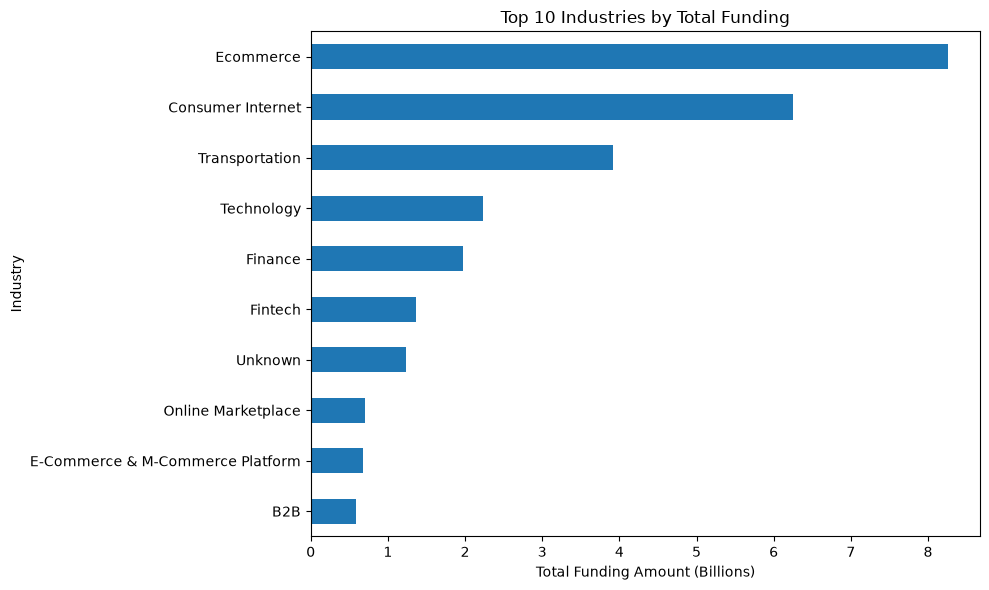

In [ ]:


top_industries = industry_funding.head(10) / 1_000_000_000

plt.figure(figsize=(10, 6))

top_industries.sort_values().plot(kind="barh")

plt.title("Top 10 Industries by Total Funding")
plt.xlabel("Total Funding Amount (Billions)")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

### 7. City-wise Total Funding Analysis

This analysis examines the total funding amounts recorded for startups across different cities. It helps identify the major startup funding hubs based on the available dataset.

In [ ]:


city_funding = (
    df_processed.groupby("City_Cleaned")["Amount_Cleaned"]
    .sum()
    .sort_values(ascending=False)
)


display(city_funding.head(10))

City_Cleaned
Bengaluru     18474508863.0
Mumbai         4921185015.0
Gurugram      3871228657.54
New Delhi      3017816875.0
Unknown        1271863868.0
Noida          1262864000.0
Chennai         718767000.0
Pune            633082000.0
Menlo Park      450000000.0
Hyderabad       401076230.0
Name: Amount_Cleaned, dtype: Float64

### 8. Top 10 Cities by Total Funding

A horizontal bar chart is used to compare the top 10 cities based on their total recorded funding amounts. It helps identify the major startup funding hubs in the dataset.

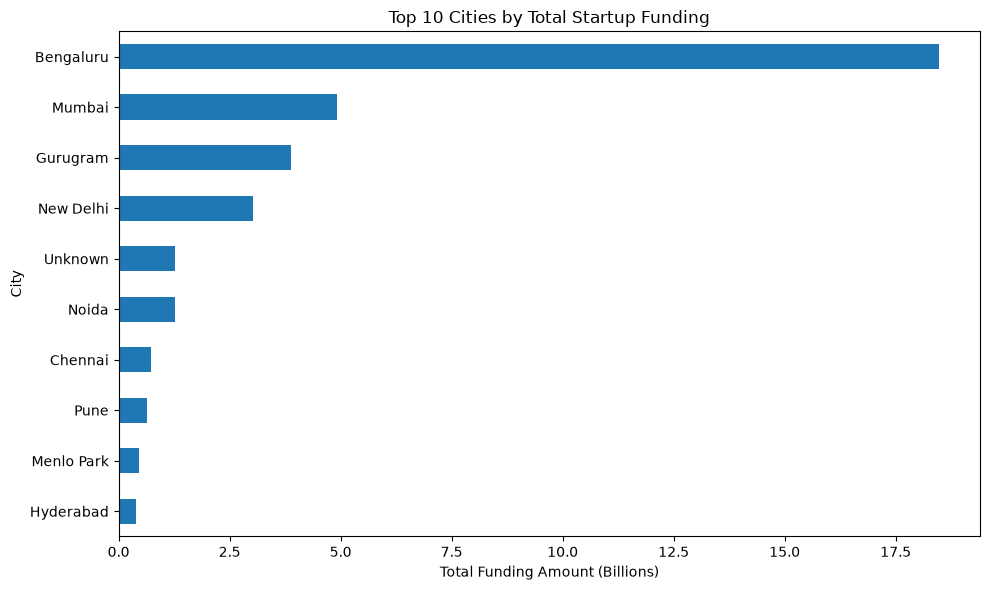

In [ ]:


top_cities = city_funding.head(10) / 1_000_000_000

plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Total Startup Funding")
plt.xlabel("Total Funding Amount (Billions)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

### 9. Investment Type-wise Funding Analysis

This analysis examines the total funding amounts associated with different investment types. It helps us understand the contribution of funding categories such as Seed Funding, Private Equity, Seed/Angel Funding and Debt Funding.

In [ ]:


investment_funding = (
    df_processed.groupby("Investment_Type_Cleaned")["Amount_Cleaned"]
    .sum()
    .sort_values(ascending=False)
)



display(investment_funding.head(10))

Investment_Type_Cleaned
Private Equity        27164318165.0
Series B               4799195735.0
Series D               1481799000.0
Series C               1044718394.0
Funding Round          1000000000.0
Seed Funding            580235908.0
Series G                231000000.0
Seed/Angel Funding      225696010.0
Unknown                207629010.22
Series A                203200000.0
Name: Amount_Cleaned, dtype: Float64

### 10. Top 10 Investment Types by Total Funding

A horizontal bar chart is used to compare the top 10 investment types based on their total recorded funding amounts. It helps identify the investment categories that contributed the highest funding.

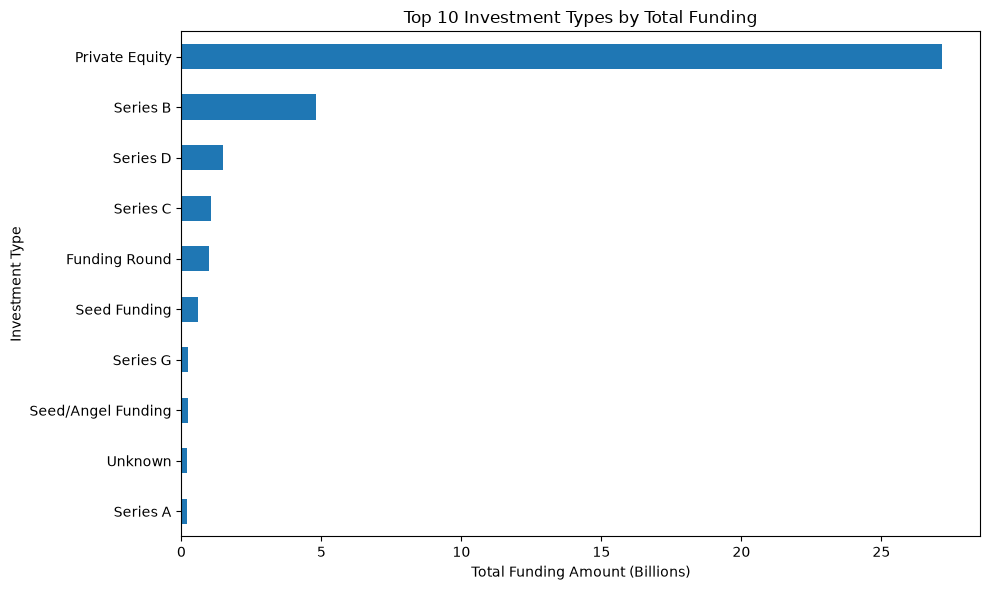

In [ ]:


top_investments = investment_funding.head(10) / 1_000_000_000

plt.figure(figsize=(10, 6))

top_investments.sort_values().plot(kind="barh")

plt.title("Top 10 Investment Types by Total Funding")
plt.xlabel("Total Funding Amount (Billions)")
plt.ylabel("Investment Type")

plt.tight_layout()
plt.show()

### 11. Top Investors by Number of Funding Records

This analysis identifies the investors who appear most frequently in the startup funding dataset. It helps us understand which investors participated in a larger number of recorded funding deals.

In [ ]:


top_investors = (
    df_processed[
        ~df_processed["Investors_Cleaned"].isin(
            ["Unknown", "Undisclosed Investors"]
        )
    ]["Investors_Cleaned"]
    .value_counts()
    .head(10)
)

display(top_investors)

Investors_Cleaned
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Venture Catalysts           11
Brand Capital               11
SAIF Partners               10
RoundGlass Partners         10
Name: count, dtype: Int64

### 13. Top Investors by Number of Funding Records

This visualization displays the top 10 investor entries based on their frequency in the dataset. It helps identify the investor names or groups that appear most often in the available funding records.

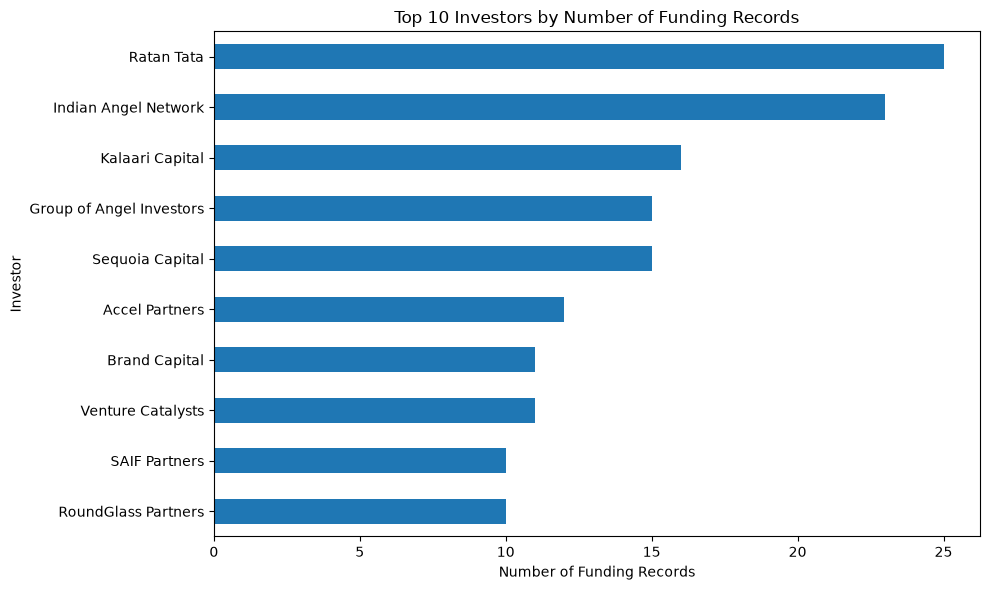

In [90]:
plt.figure(figsize=(10, 6))

top_investors.sort_values().plot(kind="barh")

plt.title("Top 10 Investors by Number of Funding Records")
plt.xlabel("Number of Funding Records")
plt.ylabel("Investor")
plt.tight_layout()
plt.show()

**Observation:**

The analysis shows that Ratan Tata appears most frequently in the funding records, with 25 entries, followed by Indian Angel Network with 23 entries. Kalaari Capital ranks third with 16 entries. Sequoia Capital and Group of Angel Investors each have 15 entries.

This analysis highlights the investor names and groups that appear most frequently in the available dataset.

### 15. Distribution of Startup Funding Amounts

This analysis examines the distribution of startup funding amounts using a histogram. It helps us understand the spread of funding values and identify whether the data is concentrated around smaller or larger amounts.

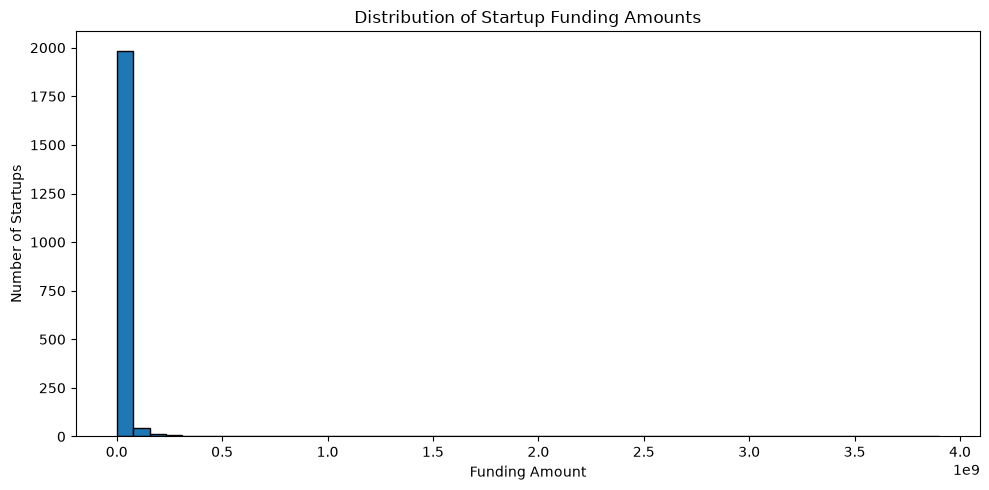

In [91]:
plt.figure(figsize=(10, 5))

df_processed["Amount_Cleaned"].dropna().plot(
    kind="hist",
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Startup Funding Amounts")
plt.xlabel("Funding Amount")
plt.ylabel("Number of Startups")
plt.tight_layout()
plt.show()

**Observation:**

The histogram shows that most startup funding amounts are concentrated in the lower range, while a small number of startups received very large funding amounts.

This indicates that the funding amount distribution is positively skewed (right-skewed). A few unusually large funding values create a long tail towards the right side of the distribution.

Therefore, the dataset contains significant variation in startup funding amounts.

### 16. Logarithmic Distribution of Startup Funding Amounts

The funding amounts contain a few very large values, making smaller values difficult to compare in a normal histogram. A logarithmic scale helps us visualize the distribution more clearly by reducing the effect of large values.

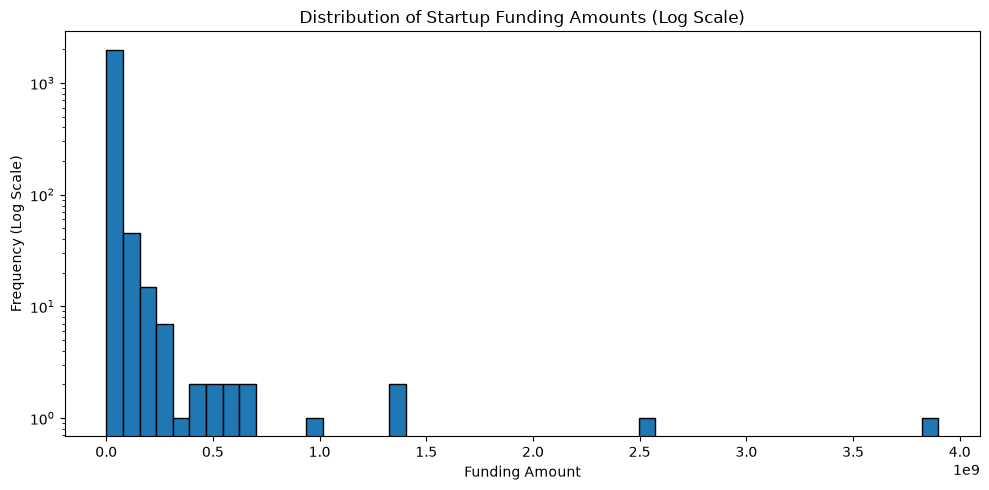

In [92]:
plt.figure(figsize=(10, 5))

df_processed["Amount_Cleaned"].dropna().plot(
    kind="hist",
    bins=50,
    logy=True,
    edgecolor="black"
)

plt.title("Distribution of Startup Funding Amounts (Log Scale)")
plt.xlabel("Funding Amount")
plt.ylabel("Frequency (Log Scale)")
plt.tight_layout()
plt.show()

**Observation:**

The logarithmic scale makes the distribution of startup funding amounts easier to visualize. It reduces the visual dominance of extremely large funding values and helps us observe the frequency of smaller funding amounts more clearly.

The distribution still shows variation in funding amounts, with a small number of startups receiving significantly higher investments.

### 17. Number of Funding Records by Investment Type

This analysis identifies how frequently different investment types appear in the dataset. It helps us understand which funding categories are most common.

In [93]:
investment_counts = (
    df_processed["Investment_Type_Cleaned"]
    .value_counts()
    .drop("Unknown", errors="ignore")
    .head(10)
)

display(investment_counts)

Investment_Type_Cleaned
Seed Funding          1387
Private Equity        1362
Seed/Angel Funding     141
Debt Funding            26
Series A                24
Series B                20
Series C                14
Series D                12
Pre-Series A             9
Seed Round               7
Name: count, dtype: Int64

### 18. Visualization of Funding Records by Investment Type

This bar chart compares the number of funding records across the top 10 investment types. It helps identify the most frequently recorded funding categories.

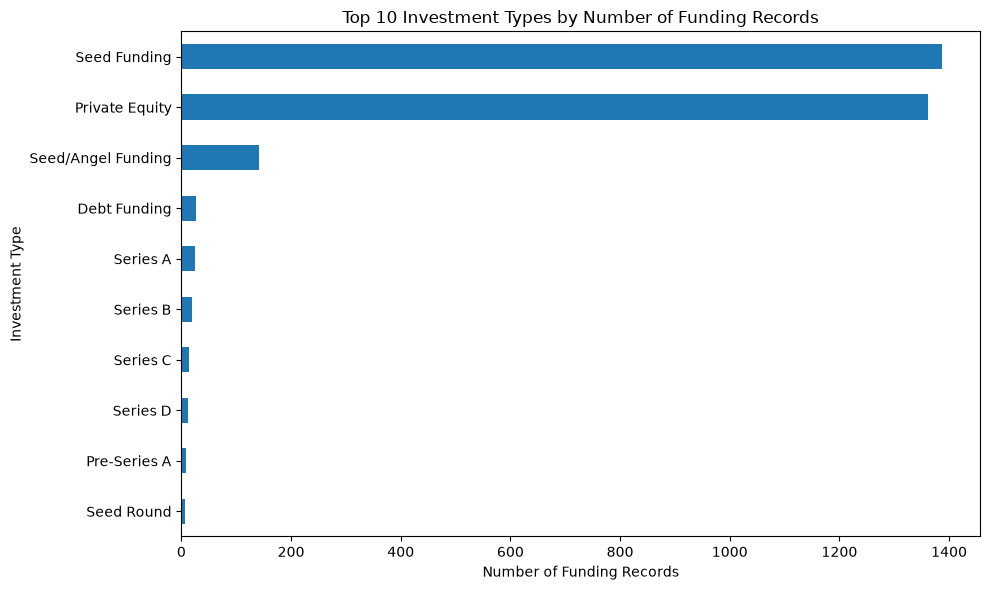

In [94]:
plt.figure(figsize=(10, 6))

investment_counts.sort_values().plot(kind="barh")

plt.title("Top 10 Investment Types by Number of Funding Records")
plt.xlabel("Number of Funding Records")
plt.ylabel("Investment Type")
plt.tight_layout()
plt.show()

**Observation:**

The analysis shows that Seed Funding has the highest number of funding records, with 1,387 entries, followed by Private Equity with 1,362 entries. Seed/Angel Funding ranks third with 141 entries.

This indicates that Seed Funding and Private Equity are the most frequently recorded investment types in the dataset. However, the most frequent investment type does not necessarily have the highest total funding amount.

### 19. Year-wise Investment Type Analysis

This analysis compares the number of funding records for different investment types across years. It helps identify changes in the popularity of funding categories over time.

In [95]:
year_investment = pd.crosstab(
    df_processed["Year"],
    df_processed["Investment_Type_Cleaned"]
)

year_investment = year_investment.drop(
    columns=["Unknown"],
    errors="ignore"
)

display(year_investment)

Investment_Type_Cleaned,Angel,Angel Funding,Angel Round,Bridge Round,Corporate Round,Crowd Funding,Debt,Debt Funding,Debt and Preference capital,Equity,...,Series F,Series G,Series H,Series J,Single Venture,Structured Debt,Term Loan,Venture,Venture - Series Unknown,Venture Round
Year,,,,,,,,,,,,,,,,,,,,,
2015,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2017,0,1,0,0,0,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,0
2018,0,0,0,0,0,0,0,9,0,2,...,0,0,0,0,0,1,1,0,0,0
2019,1,0,1,1,2,0,1,6,1,0,...,2,1,1,1,1,0,0,1,1,2
2020,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:


top_5_types = (
    df_processed["Investment_Type_Cleaned"]
    .value_counts()
    .drop("Unknown", errors="ignore")
    .head(5)
    .index
)



year_investment_top5 = year_investment[top_5_types]

display(year_investment_top5)

Investment_Type_Cleaned,Seed Funding,Private Equity,Seed/Angel Funding,Debt Funding,Series A
Year,,,,,
2015,499,435,0,0,0
2016,586,406,0,0,0
2017,290,365,20,11,0
2018,6,150,120,9,5
2019,6,4,1,6,18
2020,0,2,0,0,1


### 21. Year-wise Investment Type Comparison

This grouped bar chart compares the number of funding records for the top five investment types across different years. It helps us observe how the frequency of different funding categories changed over time.

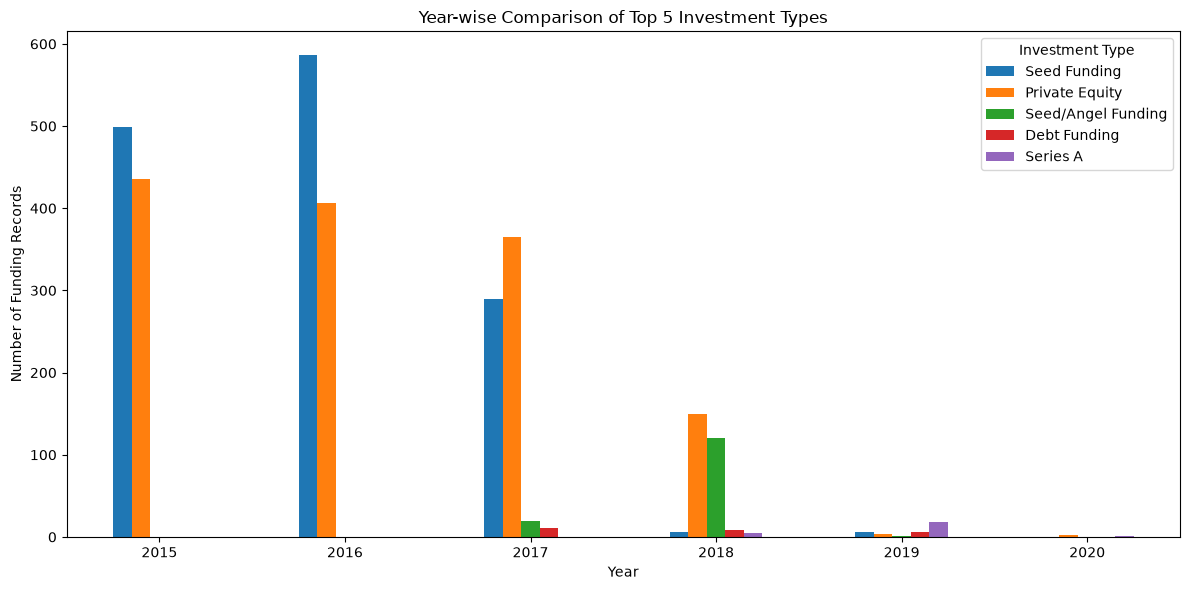

In [97]:
year_investment_top5.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Year-wise Comparison of Top 5 Investment Types")
plt.xlabel("Year")
plt.ylabel("Number of Funding Records")
plt.xticks(rotation=0)
plt.legend(title="Investment Type")
plt.tight_layout()
plt.show()

**Observation:**

The year-wise comparison shows that Seed Funding and Private Equity were the most frequently recorded investment types during 2015 and 2016.

In 2017, Private Equity had more records than Seed Funding. Seed/Angel Funding increased in 2018, while Series A became more prominent in 2019 compared with the other selected categories.

The number of records across these investment types declined considerably in 2020.